# PLN — Classificação de receitas

**Equipe:** Alana Cristina Andreazza, Beatriz Moresco Joaquim, Caio Abraão, Haiko Rudiger e Leticia Fruet

Este notebook dá continuidade ao trabalho anterior utilizando a base já coletada e pré-processada.

As etapas de **coleta, paginação, limpeza e pré-processamento não são repetidas**. A base é importada diretamente do arquivo `receitas_tudogostoso_processadas.csv`.

Nesta etapa, comparamos quatro representações textuais para a tarefa supervisionada de classificação:

- Bag of Words (BoW);
- TF-IDF;
- Word2Vec;
- BERTimbau.

Para manter a comparação justa, utilizamos a **mesma divisão de treino e teste** e o mesmo classificador, a **Regressão Logística**, nos quatro experimentos.

## 1. Preparação do ambiente

Seguimos o fluxo apresentado na Aula 08:

**texto → representação → classificador → classe prevista → avaliação**

Além das bibliotecas utilizadas na aula, usamos `gensim` para Word2Vec e `transformers` para BERTimbau.

In [ ]:
%pip -q install gensim transformers nltk

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 58.8 MB/s eta 0:00:00


In [ ]:
import ast
import io

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from gensim.models import Word2Vec
from transformers import AutoTokenizer, AutoModel

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

## 2. Importação da base processada

O notebook utiliza o CSV produzido pelo primeiro Colab. Assim, não é necessário repetir scraping, paginação ou pré-processamento.

Ao executar a célula abaixo no Google Colab, selecione o arquivo:

`receitas_tudogostoso_processadas.csv`

In [ ]:
from google.colab import files

arquivos = files.upload()

nome_csv = next(
    nome
    for nome in arquivos
    if nome.lower().endswith(".csv")
)

df = pd.read_csv(
    io.BytesIO(arquivos[nome_csv])
)

print("Arquivo carregado:", nome_csv)
print("Quantidade de receitas:", len(df))
print("Quantidade de colunas:", len(df.columns))

display(
    df[
        [
            "Categorias",
            "Título",
            "Texto para PLN",
            "tokens_sem_stopwords_pipeline",
        ]
    ].head(3)
)

Saving receitas_tudogostoso_processadas.csv to receitas_tudogostoso_processadas (1).csv
Arquivo carregado: receitas_tudogostoso_processadas (1).csv
Quantidade de receitas: 620
Quantidade de colunas: 23


,Categorias,Título,Texto para PLN,tokens_sem_stopwords_pipeline
0,['BOLOS E TORTAS'],Bolo de milho de lata no liquidificador,Bolo de milho de lata no liquidificador 1 porç...,"['bolo', 'milho', 'lata', 'liquidificador', 'p..."
1,['BOLOS E TORTAS'],Bolo de fubá simples,Bolo de fubá simples 8 porções 3 ovos 2 xícara...,"['bolo', 'fubá', 'simples', 'porções', 'ovos',..."
2,['BOLOS E TORTAS'],Brownie simples e rápido,Brownie simples e rápido 10 porções 5 colheres...,"['brownie', 'simples', 'rápido', 'porções', 'c..."


## 3. Validação dos dados necessários

Para a classificação precisamos de:

- `Texto para PLN`: texto completo da receita;
- `tokens_sem_stopwords_pipeline`: representação pré-processada já produzida no primeiro notebook;
- `Categorias`: rótulos originais da receita;
- `Título`: utilizado apenas para facilitar a análise dos resultados.

In [ ]:
COLUNAS_OBRIGATORIAS = [
    "Categorias",
    "Título",
    "Texto para PLN",
    "tokens_sem_stopwords_pipeline",
]

faltantes = [
    coluna
    for coluna in COLUNAS_OBRIGATORIAS
    if coluna not in df.columns
]

if faltantes:
    raise ValueError(
        f"Colunas obrigatórias ausentes: {faltantes}"
    )

if df["Texto para PLN"].fillna("").str.strip().eq("").any():
    raise ValueError(
        "Existem receitas sem conteúdo em 'Texto para PLN'."
    )

print("Dados necessários disponíveis.")

Dados necessários disponíveis.


## 4. Preparação dos rótulos

### Observação — receitas com mais de uma categoria

A base pode conter receitas associadas simultaneamente a mais de uma categoria. Esses registros caracterizam um problema de **classificação multirrótulo (multilabel)**.

Como a Aula 08 apresenta um problema de **classificação multiclasse**, neste experimento serão utilizadas apenas as receitas associadas a **uma única categoria**.

As receitas multirrótulo **não são removidas da base original**. Elas ficam fora somente deste experimento de classificação.

In [ ]:
df["Categorias_lista"] = df["Categorias"].apply(
    ast.literal_eval
)

quantidade_rotulos = (
    df["Categorias_lista"]
    .apply(len)
    .value_counts()
    .sort_index()
)

display(
    quantidade_rotulos
    .rename("Quantidade de receitas")
    .to_frame()
)

df_classificacao = (
    df[
        df["Categorias_lista"].apply(len) == 1
    ]
    .copy()
    .reset_index(drop=True)
)

df_classificacao["Categoria"] = (
    df_classificacao["Categorias_lista"]
    .str[0]
)

print("Receitas na base original:", len(df))
print(
    "Receitas multirrótulo fora deste experimento:",
    len(df) - len(df_classificacao)
)
print(
    "Receitas utilizadas na classificação:",
    len(df_classificacao)
)

,Quantidade de receitas
Categorias_lista,
1,580
2,40


Receitas na base original: 620
Receitas multirrótulo fora deste experimento: 40
Receitas utilizadas na classificação: 580


## 5. Distribuição das classes

Antes do treinamento, verificamos a quantidade de receitas disponível em cada categoria.

In [ ]:
distribuicao_classes = (
    df_classificacao["Categoria"]
    .value_counts()
    .sort_index()
)

display(
    distribuicao_classes
    .rename("Quantidade")
    .to_frame()
)

,Quantidade
Categoria,
ALIMENTAÇÃO SAUDÁVEL,59
AVES,49
BEBIDAS,59
BOLOS E TORTAS,57
CARNES,48
DOCES E SOBREMESAS,56
LANCHES,53
MASSAS,54
PEIXES E FRUTOS DO MAR,57


## 6. Recuperação dos tokens já processados

Os tokens já foram produzidos no primeiro notebook. Aqui apenas convertemos a representação salva no CSV de texto para lista Python.

Não repetimos tokenização, normalização ou remoção de stopwords sobre as receitas coletadas.

In [ ]:
df_classificacao["tokens_classificacao"] = (
    df_classificacao[
        "tokens_sem_stopwords_pipeline"
    ]
    .apply(ast.literal_eval)
)

df_classificacao["texto_tokens"] = (
    df_classificacao[
        "tokens_classificacao"
    ]
    .apply(lambda tokens: " ".join(tokens))
)

display(
    df_classificacao[
        [
            "Título",
            "Categoria",
            "texto_tokens",
        ]
    ].head(3)
)

,Título,Categoria,texto_tokens
0,Bolo de milho de lata no liquidificador,BOLOS E TORTAS,bolo milho lata liquidificador porção lata mil...
1,Bolo de fubá simples,BOLOS E TORTAS,bolo fubá simples porções ovos xícaras chá açú...
2,Brownie simples e rápido,BOLOS E TORTAS,brownie simples rápido porções colheres mantei...


## 7. Separação entre treino e teste

Assim como na Aula 08:

- 80% dos registros são utilizados para treinamento;
- 20% são utilizados para teste;
- `stratify` preserva aproximadamente a distribuição das categorias;
- `random_state=42` torna a divisão reproduzível.

A mesma divisão será utilizada nos quatro experimentos.

In [ ]:
indices = np.arange(
    len(df_classificacao)
)

indices_treino, indices_teste = train_test_split(
    indices,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df_classificacao["Categoria"],
)

treino = (
    df_classificacao
    .iloc[indices_treino]
    .copy()
)

teste = (
    df_classificacao
    .iloc[indices_teste]
    .copy()
)

y_train = treino["Categoria"]
y_test = teste["Categoria"]

print("Treino:", len(treino))
print("Teste:", len(teste))
print(
    "Classes:",
    sorted(df_classificacao["Categoria"].unique())
)

Treino: 464
Teste: 116
Classes: ['ALIMENTAÇÃO SAUDÁVEL', 'AVES', 'BEBIDAS', 'BOLOS E TORTAS', 'CARNES', 'DOCES E SOBREMESAS', 'LANCHES', 'MASSAS', 'PEIXES E FRUTOS DO MAR', 'SALADAS E MOLHOS', 'SOPAS']


## 8. Função comum de avaliação

Para comparar as representações de forma justa, utilizamos a mesma `LogisticRegression` em todos os experimentos.

As principais métricas são:

- **Accuracy**: proporção total de classificações corretas;
- **Precision**: entre as previsões de uma classe, quantas estavam corretas;
- **Recall**: entre os exemplos reais de uma classe, quantos foram encontrados;
- **F1-score**: equilíbrio entre precision e recall.

Como existem várias categorias, utilizamos também o **Macro F1**, que calcula o F1 de cada classe e atribui o mesmo peso a todas elas.

In [ ]:
resultados = []
modelos_classificacao = {}
previsoes = {}


def treinar_e_avaliar(
    nome,
    X_train,
    X_test,
):
    classificador = LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE,
    )

    classificador.fit(
        X_train,
        y_train,
    )

    y_pred = classificador.predict(
        X_test
    )

    modelos_classificacao[nome] = (
        classificador
    )

    previsoes[nome] = y_pred

    resultados.append({
        "Representação": nome,
        "Accuracy": accuracy_score(
            y_test,
            y_pred,
        ),
        "Precision macro": precision_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0,
        ),
        "Recall macro": recall_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0,
        ),
        "Macro F1": f1_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0,
        ),
    })

    print(f"\n{nome}")
    print("=" * len(nome))
    print(
        f"Acurácia: "
        f"{accuracy_score(y_test, y_pred):.3f}"
    )
    print(
        classification_report(
            y_test,
            y_pred,
            digits=3,
            zero_division=0,
        )
    )

    return classificador

## 9. Bag of Words + Regressão Logística

O `CountVectorizer` aprende o vocabulário **somente com o conjunto de treinamento**.

Utilizamos unigramas e bigramas, mantendo os mesmos parâmetros gerais apresentados na Aula 08 para a representação clássica.

In [ ]:
bow_vectorizer = CountVectorizer(
    lowercase=False,
    min_df=2,
    max_df=0.95,
    ngram_range=(1, 2),
    max_features=20_000,
)

X_train_bow = (
    bow_vectorizer.fit_transform(
        treino["texto_tokens"]
    )
)

X_test_bow = (
    bow_vectorizer.transform(
        teste["texto_tokens"]
    )
)

modelo_bow = treinar_e_avaliar(
    "BoW",
    X_train_bow,
    X_test_bow,
)

print(
    "Vocabulário BoW:",
    len(bow_vectorizer.get_feature_names_out())
)


BoW
===
Acurácia: 0.724
                        precision    recall  f1-score   support

  ALIMENTAÇÃO SAUDÁVEL      1.000     0.583     0.737        12
                  AVES      0.727     0.800     0.762        10
               BEBIDAS      0.750     1.000     0.857        12
        BOLOS E TORTAS      0.875     0.636     0.737        11
                CARNES      0.769     1.000     0.870        10
    DOCES E SOBREMESAS      0.692     0.818     0.750        11
               LANCHES      0.692     0.818     0.750        11
                MASSAS      0.583     0.636     0.609        11
PEIXES E FRUTOS DO MAR      0.818     0.818     0.818        11
      SALADAS E MOLHOS      0.429     0.333     0.375         9
                 SOPAS      0.600     0.375     0.462         8

              accuracy                          0.724       116
             macro avg      0.721     0.711     0.702       116
          weighted avg      0.732     0.724     0.714       116

Vocabulário 

## 10. TF-IDF + Regressão Logística

O TF-IDF utiliza o mesmo texto e o mesmo conjunto de treino do BoW. A diferença está na forma como os termos são ponderados.

O vetorizador também é ajustado apenas com os dados de treinamento, evitando utilizar informações do conjunto de teste durante o aprendizado.

In [ ]:
tfidf_vectorizer = TfidfVectorizer(
    lowercase=False,
    min_df=2,
    max_df=0.95,
    ngram_range=(1, 2),
    max_features=20_000,
)

X_train_tfidf = (
    tfidf_vectorizer.fit_transform(
        treino["texto_tokens"]
    )
)

X_test_tfidf = (
    tfidf_vectorizer.transform(
        teste["texto_tokens"]
    )
)

modelo_tfidf = treinar_e_avaliar(
    "TF-IDF",
    X_train_tfidf,
    X_test_tfidf,
)

print(
    "Vocabulário TF-IDF:",
    len(tfidf_vectorizer.get_feature_names_out())
)


TF-IDF
Acurácia: 0.733
                        precision    recall  f1-score   support

  ALIMENTAÇÃO SAUDÁVEL      0.714     0.417     0.526        12
                  AVES      0.667     1.000     0.800        10
               BEBIDAS      0.846     0.917     0.880        12
        BOLOS E TORTAS      0.900     0.818     0.857        11
                CARNES      0.833     1.000     0.909        10
    DOCES E SOBREMESAS      0.714     0.909     0.800        11
               LANCHES      0.727     0.727     0.727        11
                MASSAS      0.545     0.545     0.545        11
PEIXES E FRUTOS DO MAR      0.733     1.000     0.846        11
      SALADAS E MOLHOS      0.500     0.222     0.308         9
                 SOPAS      0.750     0.375     0.500         8

              accuracy                          0.733       116
             macro avg      0.721     0.721     0.700       116
          weighted avg      0.725     0.733     0.709       116

Vocabulário T

## 11. Word2Vec + Regressão Logística

Assim como no primeiro notebook, utilizamos Word2Vec com Skip-gram e representamos cada receita pela média dos vetores de suas palavras.

Nesta etapa existe uma diferença importante: o Word2Vec é treinado **somente com as receitas do conjunto de treinamento**.

Palavras presentes apenas no teste podem ficar fora do vocabulário do modelo (OOV).

In [ ]:
modelo_w2v = Word2Vec(
    sentences=treino[
        "tokens_classificacao"
    ].tolist(),
    vector_size=190,
    window=5,
    min_count=1,
    sg=1,
    seed=RANDOM_STATE,
    workers=1,
    epochs=200,
)


def representar_documento_word2vec(
    tokens,
):
    vetores = [
        modelo_w2v.wv[token]
        for token in tokens
        if token in modelo_w2v.wv
    ]

    if not vetores:
        return np.zeros(
            modelo_w2v.vector_size,
            dtype=float,
        )

    return np.mean(
        vetores,
        axis=0,
    )


X_train_w2v = np.vstack(
    treino[
        "tokens_classificacao"
    ].apply(
        representar_documento_word2vec
    )
)

X_test_w2v = np.vstack(
    teste[
        "tokens_classificacao"
    ].apply(
        representar_documento_word2vec
    )
)

modelo_classificacao_w2v = (
    treinar_e_avaliar(
        "Word2Vec",
        X_train_w2v,
        X_test_w2v,
    )
)

tokens_teste = [
    token
    for tokens in teste[
        "tokens_classificacao"
    ]
    for token in tokens
]

oov_teste = [
    token
    for token in tokens_teste
    if token not in modelo_w2v.wv
]

print(
    "Proporção de tokens OOV no teste:",
    f"{len(oov_teste) / max(len(tokens_teste), 1):.2%}",
)


Word2Vec
Acurácia: 0.724
                        precision    recall  f1-score   support

  ALIMENTAÇÃO SAUDÁVEL      0.667     0.333     0.444        12
                  AVES      0.833     1.000     0.909        10
               BEBIDAS      0.818     0.750     0.783        12
        BOLOS E TORTAS      0.900     0.818     0.857        11
                CARNES      0.750     0.900     0.818        10
    DOCES E SOBREMESAS      0.643     0.818     0.720        11
               LANCHES      0.667     0.545     0.600        11
                MASSAS      0.533     0.727     0.615        11
PEIXES E FRUTOS DO MAR      0.786     1.000     0.880        11
      SALADAS E MOLHOS      0.750     0.333     0.462         9
                 SOPAS      0.667     0.750     0.706         8

              accuracy                          0.724       116
             macro avg      0.728     0.725     0.709       116
          weighted avg      0.729     0.724     0.709       116

Proporção d

## 12. BERTimbau + Regressão Logística

Utilizamos o mesmo modelo do trabalho anterior:

`neuralmind/bert-base-portuguese-cased`

O BERTimbau **não é treinado do zero com as receitas**. Ele é utilizado para gerar embeddings dos textos, e a Regressão Logística aprende a classificação a partir dos embeddings das receitas de treinamento.

Antes da geração dos embeddings, verificamos o tamanho dos textos e selecionamos o menor limite entre 128, 256 e o máximo suportado pelo modelo que comporte pelo menos 90% das receitas.

In [ ]:
MODELO_BERT = (
    "neuralmind/"
    "bert-base-portuguese-cased"
)

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

tokenizer_bert = (
    AutoTokenizer.from_pretrained(
        MODELO_BERT
    )
)

modelo_bert = (
    AutoModel.from_pretrained(
        MODELO_BERT
    )
    .to(device)
)

modelo_bert.eval()

textos_bert = (
    df_classificacao[
        "Texto para PLN"
    ]
    .fillna("")
    .astype(str)
    .tolist()
)

codificados = tokenizer_bert(
    textos_bert,
    add_special_tokens=True,
    truncation=False,
)

comprimentos_bert = np.array([
    len(ids)
    for ids in codificados["input_ids"]
])

limite_modelo = min(
    int(tokenizer_bert.model_max_length),
    512,
)

candidatos = sorted(
    set([
        128,
        256,
        limite_modelo,
    ])
)

MAX_LENGTH_BERT = limite_modelo

for candidato in candidatos:
    proporcao = (
        comprimentos_bert <= candidato
    ).mean()

    if proporcao >= 0.90:
        MAX_LENGTH_BERT = candidato
        break

resumo_bert = pd.DataFrame([{
    "mínimo": int(comprimentos_bert.min()),
    "mediana": float(
        np.median(comprimentos_bert)
    ),
    "p90": float(
        np.percentile(
            comprimentos_bert,
            90,
        )
    ),
    "p95": float(
        np.percentile(
            comprimentos_bert,
            95,
        )
    ),
    "máximo": int(
        comprimentos_bert.max()
    ),
    "% acima de 128": round(
        100 * (
            comprimentos_bert > 128
        ).mean(),
        2,
    ),
    "% acima de 256": round(
        100 * (
            comprimentos_bert > 256
        ).mean(),
        2,
    ),
    "% acima de 512": round(
        100 * (
            comprimentos_bert > 512
        ).mean(),
        2,
    ),
}])

display(resumo_bert)

print("Dispositivo:", device)
print(
    "max_length adotado:",
    MAX_LENGTH_BERT,
)

config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

...

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

,mínimo,mediana,p90,p95,máximo,% acima de 128,% acima de 256,% acima de 512
0,60,203.0,354.5,439.0,1202,86.72,28.28,2.07


Dispositivo: cpu
max_length adotado: 512


In [ ]:
def mean_pooling(
    last_hidden_state,
    attention_mask,
):
    mascara = (
        attention_mask
        .unsqueeze(-1)
        .expand(
            last_hidden_state.size()
        )
        .float()
    )

    soma = torch.sum(
        last_hidden_state * mascara,
        dim=1,
    )

    quantidade = torch.clamp(
        mascara.sum(dim=1),
        min=1e-9,
    )

    return soma / quantidade


def gerar_embeddings_bert(
    textos,
    batch_size=8,
):
    todos_embeddings = []

    for inicio in range(
        0,
        len(textos),
        batch_size,
    ):
        lote = textos[
            inicio:inicio + batch_size
        ]

        entradas = tokenizer_bert(
            lote,
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH_BERT,
            return_tensors="pt",
        )

        entradas = {
            chave: valor.to(device)
            for chave, valor
            in entradas.items()
        }

        with torch.no_grad():
            saida = modelo_bert(
                **entradas
            )

        embeddings_lote = mean_pooling(
            saida.last_hidden_state,
            entradas[
                "attention_mask"
            ],
        )

        todos_embeddings.append(
            embeddings_lote
            .cpu()
            .numpy()
        )

    return np.vstack(
        todos_embeddings
    )

In [ ]:
X_train_bert = gerar_embeddings_bert(
    treino[
        "Texto para PLN"
    ]
    .fillna("")
    .astype(str)
    .tolist()
)

X_test_bert = gerar_embeddings_bert(
    teste[
        "Texto para PLN"
    ]
    .fillna("")
    .astype(str)
    .tolist()
)

modelo_classificacao_bert = (
    treinar_e_avaliar(
        "BERT",
        X_train_bert,
        X_test_bert,
    )
)

print(
    "Formato treino BERT:",
    X_train_bert.shape,
)
print(
    "Formato teste BERT:",
    X_test_bert.shape,
)


BERT
====
Acurácia: 0.664
                        precision    recall  f1-score   support

  ALIMENTAÇÃO SAUDÁVEL      0.667     0.333     0.444        12
                  AVES      0.643     0.900     0.750        10
               BEBIDAS      0.800     1.000     0.889        12
        BOLOS E TORTAS      1.000     0.727     0.842        11
                CARNES      0.500     0.500     0.500        10
    DOCES E SOBREMESAS      0.909     0.909     0.909        11
               LANCHES      0.700     0.636     0.667        11
                MASSAS      0.615     0.727     0.667        11
PEIXES E FRUTOS DO MAR      0.556     0.909     0.690        11
      SALADAS E MOLHOS      0.500     0.222     0.308         9
                 SOPAS      0.286     0.250     0.267         8

              accuracy                          0.664       116
             macro avg      0.652     0.647     0.630       116
          weighted avg      0.667     0.664     0.646       116

Formato tr

## 13. Comparação das representações

Como as quatro representações utilizaram a mesma divisão de treino/teste e a mesma Regressão Logística, podemos comparar seus resultados diretamente.

O **Macro F1** será utilizado como principal referência para identificar a representação com melhor equilíbrio entre as 11 categorias. A acurácia também é apresentada.

In [ ]:
df_resultados = (
    pd.DataFrame(resultados)
    .sort_values(
        "Macro F1",
        ascending=False,
    )
    .reset_index(drop=True)
)

for coluna in [
    "Accuracy",
    "Precision macro",
    "Recall macro",
    "Macro F1",
]:
    df_resultados[coluna] = (
        df_resultados[coluna]
        .round(3)
    )

display(df_resultados)

MELHOR_REPRESENTACAO = (
    df_resultados
    .iloc[0]["Representação"]
)

print(
    "Melhor representação pelo Macro F1:",
    MELHOR_REPRESENTACAO,
)

,Representação,Accuracy,Precision macro,Recall macro,Macro F1
0,Word2Vec,0.724,0.728,0.725,0.709
1,BoW,0.724,0.721,0.711,0.702
2,TF-IDF,0.733,0.721,0.721,0.700
3,BERT,0.664,0.652,0.647,0.630


Melhor representação pelo Macro F1: Word2Vec


## 14. Matrizes de confusão

A matriz de confusão permite observar **quais categorias são confundidas entre si**.

Os gráficos abaixo devem ser analisados em conjunto com Accuracy e F1, e não isoladamente.

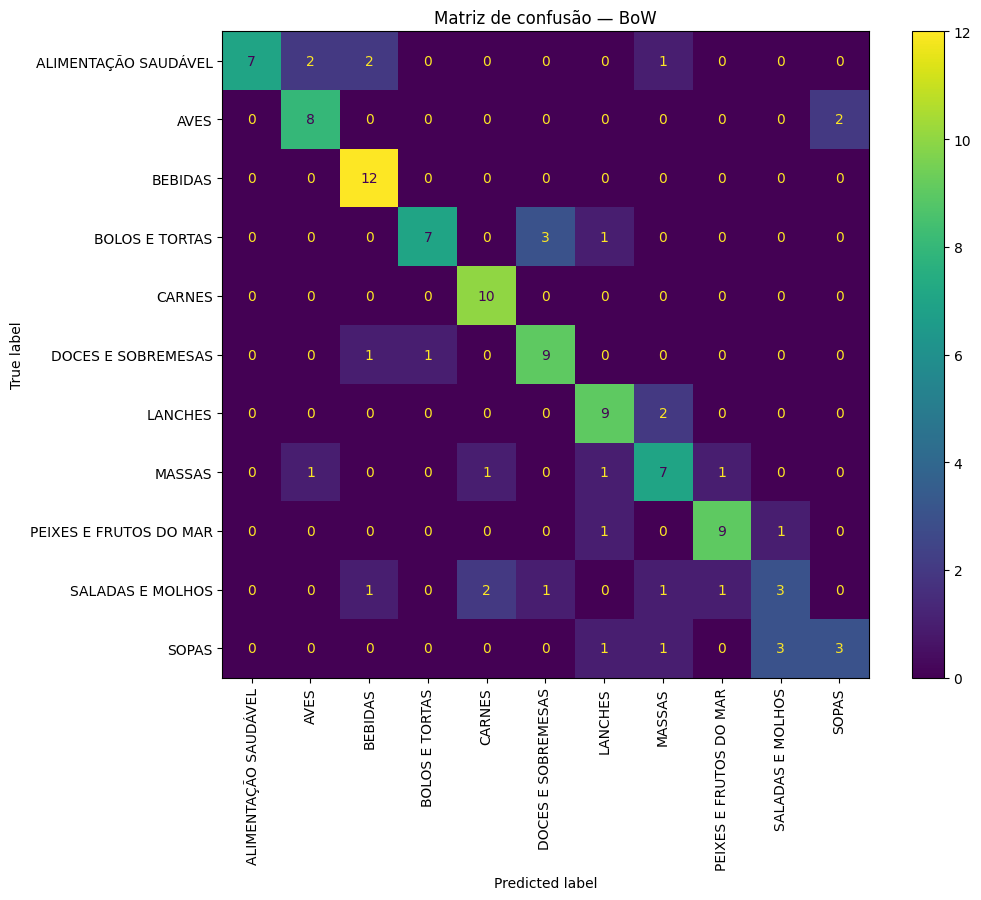

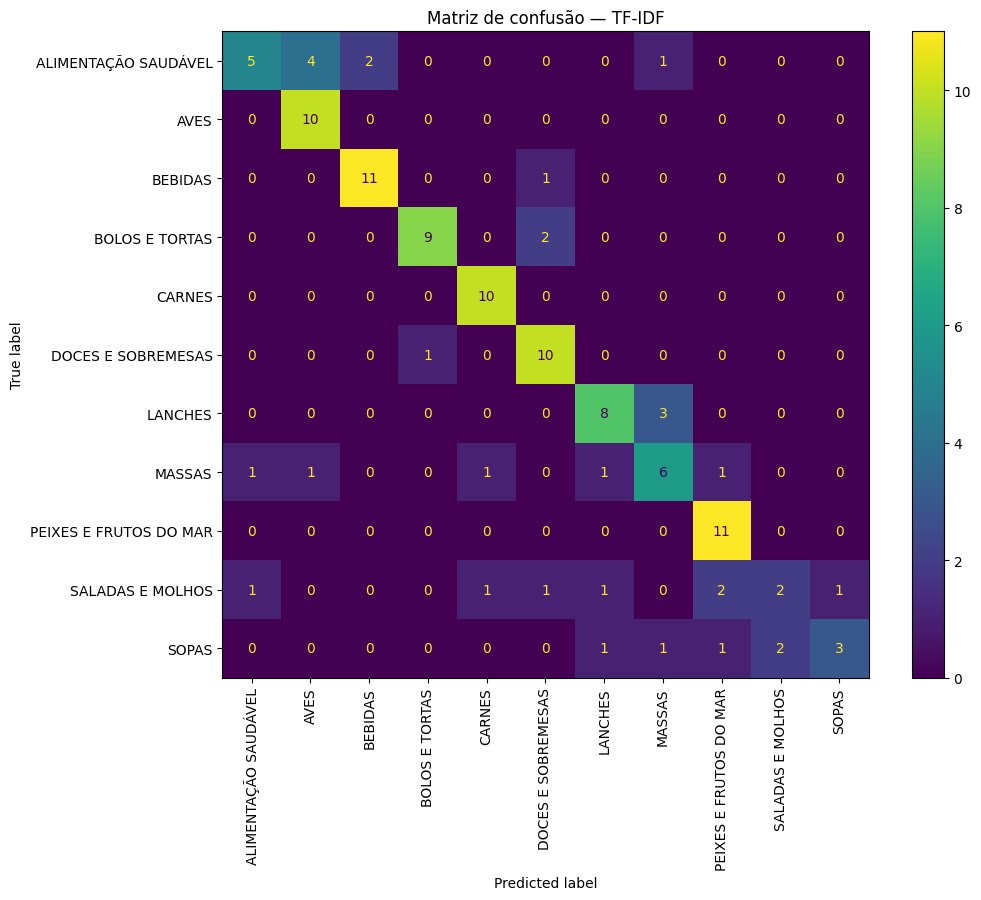

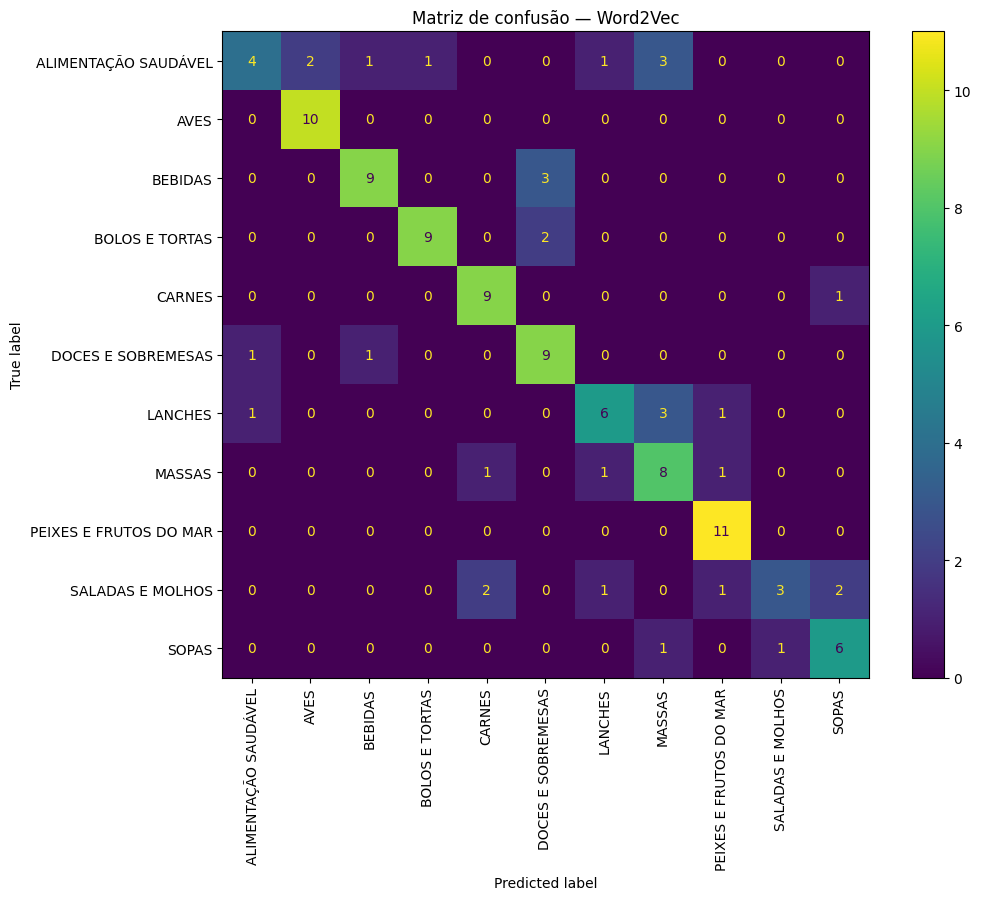

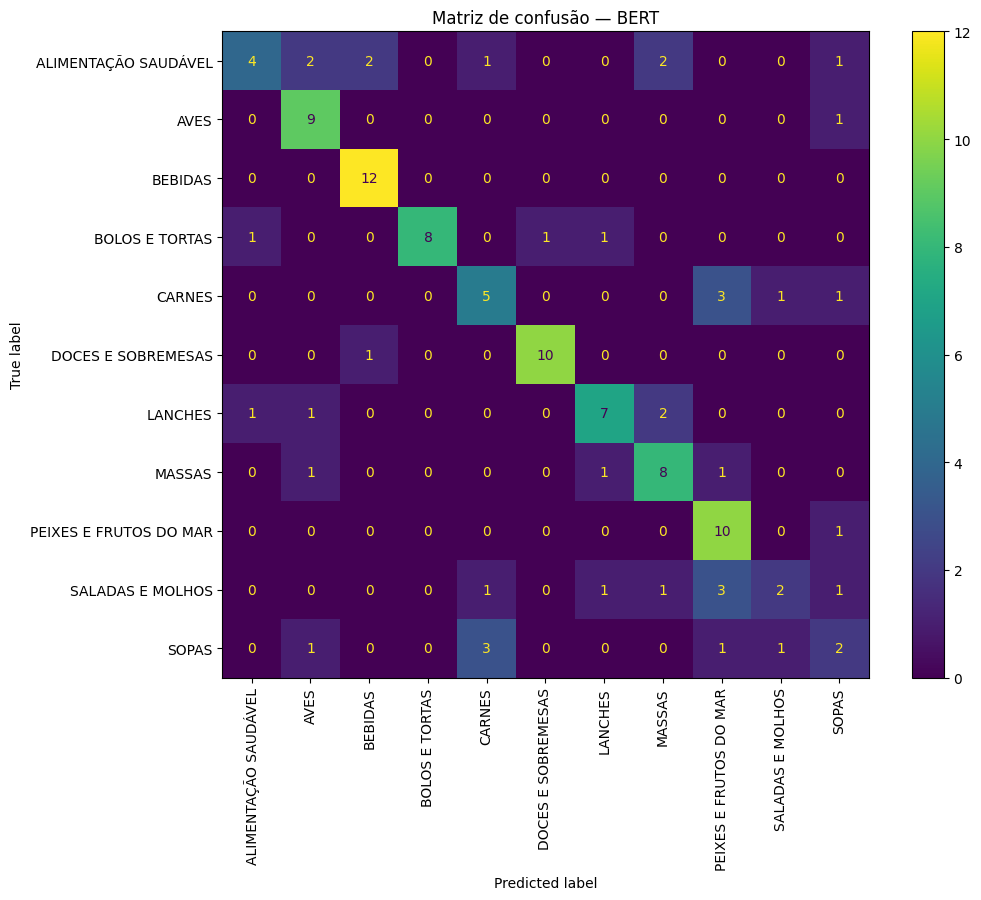

In [ ]:
for nome in [
    "BoW",
    "TF-IDF",
    "Word2Vec",
    "BERT",
]:
    fig, ax = plt.subplots(
        figsize=(11, 9)
    )

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        previsoes[nome],
        xticks_rotation=90,
        ax=ax,
    )

    ax.set_title(
        f"Matriz de confusão — {nome}"
    )

    plt.tight_layout()
    plt.show()

## 15. Análise dos erros do melhor resultado

Além das métricas, é importante observar exemplos concretos em que o classificador errou.

A tabela abaixo mostra o título da receita, a categoria real e a categoria prevista pela representação com maior Macro F1.

In [ ]:
erros = teste[
    [
        "Título",
        "Categoria",
    ]
].copy()

erros["Categoria prevista"] = (
    previsoes[
        MELHOR_REPRESENTACAO
    ]
)

erros = erros[
    erros["Categoria"]
    != erros["Categoria prevista"]
]

print(
    "Quantidade de erros:",
    len(erros),
)

display(
    erros.head(20)
)

Quantidade de erros: 32


,Título,Categoria,Categoria prevista
563,Peito de frango na Air fryer,ALIMENTAÇÃO SAUDÁVEL,AVES
531,Coxinha fit (pré-treino),ALIMENTAÇÃO SAUDÁVEL,AVES
324,Lasanha de berinjela,MASSAS,PEIXES E FRUTOS DO MAR
501,Esfirra fofinha da mamãe,LANCHES,MASSAS
359,Chocolate quente sem leite ou leite condensado,BEBIDAS,DOCES E SOBREMESAS
82,Vaca atolada,CARNES,SOPAS
572,Coxinha low carb,ALIMENTAÇÃO SAUDÁVEL,MASSAS
341,Macarrão da panela de pressão,MASSAS,CARNES
528,Picolé salada de frutas,ALIMENTAÇÃO SAUDÁVEL,BEBIDAS
465,Maçã do amor,DOCES E SOBREMESAS,ALIMENTAÇÃO SAUDÁVEL


## 16. Teste com receitas novas

O conjunto de teste já contém receitas não utilizadas no treinamento e é a base principal para avaliar o classificador.

Como demonstração adicional, testamos abaixo alguns textos criados especificamente para esta célula. Esses exemplos **não participaram do treinamento nem da avaliação quantitativa**.

Para BoW, TF-IDF e Word2Vec, os novos textos precisam passar pelo mesmo pré-processamento utilizado anteriormente. Essa pequena função é usada somente para os exemplos novos; o pré-processamento das receitas coletadas não é repetido.

In [ ]:
import nltk

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

for recurso in [
    "punkt",
    "punkt_tab",
    "stopwords",
]:
    nltk.download(
        recurso,
        quiet=True,
    )

STOPWORDS_PT = set(
    stopwords.words("portuguese")
)

STOPWORDS_RECEITAS = (
    STOPWORDS_PT
    - {"não", "nao", "sem"}
)


def preparar_novo_texto(
    texto,
):
    tokens = word_tokenize(
        texto,
        language="portuguese",
    )

    normalizados = [
        token.casefold()
        for token in tokens
        if token.isalpha()
    ]

    return [
        token
        for token in normalizados
        if token
        not in STOPWORDS_RECEITAS
    ]

In [ ]:
novas_receitas = pd.DataFrame([
    {
        "Título": "Exemplo — sopa de legumes",
        "Categoria esperada": "SOPAS",
        "Texto": (
            "Sopa de legumes com batata, cenoura, "
            "abobrinha e caldo. Cozinhe os legumes "
            "em uma panela até ficarem macios."
        ),
    },
    {
        "Título": "Exemplo — suco de laranja",
        "Categoria esperada": "BEBIDAS",
        "Texto": (
            "Suco de laranja gelado preparado com "
            "laranjas, água e gelo. Bata e sirva."
        ),
    },
    {
        "Título": "Exemplo — filé de peixe assado",
        "Categoria esperada": "PEIXES E FRUTOS DO MAR",
        "Texto": (
            "Filé de peixe temperado com limão, "
            "alho e sal, assado no forno."
        ),
    },
    {
        "Título": "Exemplo — frango assado",
        "Categoria esperada": "AVES",
        "Texto": (
            "Frango assado no forno com alho, "
            "cebola, ervas e batatas."
        ),
    },
])

display(novas_receitas)

,Título,Categoria esperada,Texto
0,Exemplo — sopa de legumes,SOPAS,"Sopa de legumes com batata, cenoura, abobrinha..."
1,Exemplo — suco de laranja,BEBIDAS,"Suco de laranja gelado preparado com laranjas,..."
2,Exemplo — filé de peixe assado,PEIXES E FRUTOS DO MAR,"Filé de peixe temperado com limão, alho e sal,..."
3,Exemplo — frango assado,AVES,"Frango assado no forno com alho, cebola, ervas..."


In [ ]:
def prever_novas_receitas():
    resultados_novos = []

    for _, receita in (
        novas_receitas.iterrows()
    ):
        texto_original = receita["Texto"]

        tokens = preparar_novo_texto(
            texto_original
        )

        texto_processado = " ".join(
            tokens
        )

        representacoes_nova = {
            "BoW": (
                bow_vectorizer.transform(
                    [texto_processado]
                )
            ),
            "TF-IDF": (
                tfidf_vectorizer.transform(
                    [texto_processado]
                )
            ),
            "Word2Vec": np.vstack([
                representar_documento_word2vec(
                    tokens
                )
            ]),
            "BERT": gerar_embeddings_bert(
                [texto_original]
            ),
        }

        for nome, vetor in (
            representacoes_nova.items()
        ):
            modelo = (
                modelos_classificacao[nome]
            )

            classe = modelo.predict(
                vetor
            )[0]

            confianca = (
                modelo.predict_proba(
                    vetor
                )
                .max()
            )

            resultados_novos.append({
                "Receita": receita["Título"],
                "Categoria esperada": receita[
                    "Categoria esperada"
                ],
                "Representação": nome,
                "Categoria prevista": classe,
                "Confiança": round(
                    float(confianca),
                    3,
                ),
            })

    return pd.DataFrame(
        resultados_novos
    )


df_novas_previsoes = (
    prever_novas_receitas()
)

display(df_novas_previsoes)

,Receita,Categoria esperada,Representação,Categoria prevista,Confiança
0,Exemplo — sopa de legumes,SOPAS,BoW,BEBIDAS,0.452
1,Exemplo — sopa de legumes,SOPAS,TF-IDF,SOPAS,0.165
2,Exemplo — sopa de legumes,SOPAS,Word2Vec,SOPAS,0.792
3,Exemplo — sopa de legumes,SOPAS,BERT,SOPAS,0.731
4,Exemplo — suco de laranja,BEBIDAS,BoW,BEBIDAS,0.836
5,Exemplo — suco de laranja,BEBIDAS,TF-IDF,BEBIDAS,0.375
6,Exemplo — suco de laranja,BEBIDAS,Word2Vec,BEBIDAS,0.750
7,Exemplo — suco de laranja,BEBIDAS,BERT,BEBIDAS,0.972
8,Exemplo — filé de peixe assado,PEIXES E FRUTOS DO MAR,BoW,BEBIDAS,0.345
9,Exemplo — filé de peixe assado,PEIXES E FRUTOS DO MAR,TF-IDF,PEIXES E FRUTOS DO MAR,0.352


## 17. Síntese

A comparação final deve considerar:

1. **Accuracy**;
2. **Macro F1**;
3. desempenho por categoria no `classification_report`;
4. padrões observados nas matrizes de confusão;
5. exemplos de erros;
6. comportamento qualitativo nos textos novos.

A representação considerada mais adequada para a classificação deve ser escolhida a partir dos resultados executados neste notebook, e não definida antecipadamente.

### Pontos para discussão no Trabalho 03

- Foi possível treinar um classificador porque a base possui categorias que podem ser utilizadas como rótulos.
- Neste experimento multiclasse, receitas com múltiplas categorias foram mantidas na base original, mas não utilizadas no treinamento.
- BoW, TF-IDF, Word2Vec e BERTimbau foram comparados com a mesma Regressão Logística.
- O conjunto de teste contém dados que o classificador não viu durante o treinamento.
- O BERTimbau foi utilizado como gerador de embeddings; não foi realizado fine-tuning do modelo.

## 18. Exportação dos resultados

Os principais resultados podem ser salvos para apoiar a escrita do Trabalho 03.

In [ ]:
df_resultados.to_csv(
    "resultados_classificacao.csv",
    index=False,
)

erros.to_csv(
    "erros_classificacao_melhor_modelo.csv",
    index=False,
)

df_novas_previsoes.to_csv(
    "previsoes_receitas_novas.csv",
    index=False,
)

print("Arquivos gerados:")
print("- resultados_classificacao.csv")
print("- erros_classificacao_melhor_modelo.csv")
print("- previsoes_receitas_novas.csv")

Arquivos gerados:
- resultados_classificacao.csv
- erros_classificacao_melhor_modelo.csv
- previsoes_receitas_novas.csv


# Continuidade — NER e extração de relações em receitas

## 19. Preparação do ambiente e leitura dos dados

**Objetivo:** preparar as bibliotecas da Aula 09 e recuperar diretamente os textos já coletados.

**Método:** Pandas para consultar o CSV, `ast.literal_eval` para reconstruir as listas textuais e spaCy com `pt_core_news_sm`, que é a família de ferramentas apresentada pelo professor. Não repetimos tokenização, lematização ou treinamento de representações vetoriais da etapa anterior.

In [ ]:
%pip -q install "spacy>=3.7,<4"

In [ ]:
import ast
import sys
import subprocess
from pathlib import Path

import pandas as pd
import spacy
from IPython.display import display

colunas = ["Título", "Categorias", "Ingredientes", "Etapas do preparo", "Texto para PLN"]

# Reutiliza o CSV já carregado na parte de classificação quando possível.
if "df" in globals() and set(colunas).issubset(df.columns):
    dados_aula09 = df.copy()
    origem_dados_aula09 = "DataFrame df (CSV carregado anteriormente)"
else:
    candidatos = [
        Path("receitas_tudogostoso_processadas.csv"),
        Path("receitas_tudogostoso_processadas(1).csv"),
    ]
    arquivo_csv = next((p for p in candidatos if p.is_file()), None)
    if arquivo_csv is None:
        raise FileNotFoundError(
            "Coloque receitas_tudogostoso_processadas.csv na pasta do notebook "
            "ou execute previamente a célula de importação da classificação."
        )
    dados_aula09 = pd.read_csv(arquivo_csv, encoding="utf-8-sig")
    origem_dados_aula09 = str(arquivo_csv)

faltantes_aula09 = [c for c in colunas if c not in dados_aula09.columns]
if faltantes_aula09:
    raise ValueError(f"Colunas necessárias não encontradas: {faltantes_aula09}")

print("Origem:", origem_dados_aula09)
print("Receitas:", len(dados_aula09))
print("Campos disponíveis para a análise:")
display(dados_aula09[colunas].head(2))

Origem: receitas_tudogostoso_processadas.csv
Receitas: 620
Campos disponíveis para a análise:


,Título,Categorias,Ingredientes,Etapas do preparo,Texto para PLN
0,Bolo de milho de lata no liquidificador,['BOLOS E TORTAS'],"['1 lata de milho (sem o líquido)', '1 lata de...",['Escorra o milho e use a própria lata para as...,Bolo de milho de lata no liquidificador 1 porç...
1,Bolo de fubá simples,['BOLOS E TORTAS'],"['3 ovos', '2 xícaras (chá) de açúcar', '2 xíc...",['Bata todos os ingredientes no liquidificador...,Bolo de fubá simples 8 porções 3 ovos 2 xícara...


In [ ]:
# O modelo `pt_core_news_sm` oferece **parser de dependências** e **NER**. A
# instalação é realizada apenas quando o modelo ainda não está disponível.

try:
    nlp_aula09 = spacy.load("pt_core_news_sm")
except OSError:
    print("Modelo de português não encontrado; iniciando instalação...")
    subprocess.run(
        [sys.executable, "-m", "spacy", "download", "pt_core_news_sm"],
        check=True,
    )
    nlp_aula09 = spacy.load("pt_core_news_sm")

if not {"parser", "ner"}.issubset(set(nlp_aula09.pipe_names)):
    raise RuntimeError("O modelo carregado precisa oferecer parser e NER.")

print("spaCy:", spacy.__version__)
print("Modelo:", nlp_aula09.meta.get("name"), nlp_aula09.meta.get("version"))
print("Componentes:", nlp_aula09.pipe_names)
print("Rótulos de NER disponíveis:", nlp_aula09.get_pipe("ner").labels)

Modelo de português não encontrado; iniciando instalação...
spaCy: 3.8.16
Modelo: core_news_sm 3.8.0
Componentes: ['tok2vec', 'morphologizer', 'parser', 'lemmatizer', 'attribute_ruler', 'ner']
Rótulos de NER disponíveis: ('LOC', 'MISC', 'ORG', 'PER')


## 20. Definição de amostra reproduzível

**Objetivo:** executar a análise de forma didática, com custo computacional moderado, mantendo diversidade de categorias.

O enunciado permite utilizar **amostras menores desde que explicitadas**. São selecionadas até **cinco receitas por categoria principal**. Em cada receita, são examinados o título e até os três primeiros passos do preparo. A categoria principal é usada **somente para estratificar esta amostragem**; receitas com mais de uma categoria não são removidas da base.

Como o CSV armazena as listas em formato de texto, é necessário convertê-las. A escolha da amostra não equivale a um conjunto de teste supervisionado nem fornece estimativas de precisão/recall de NER.

In [ ]:
def converter_lista_segura(valor):
    if isinstance(valor, list):
        return valor
    if pd.isna(valor) or str(valor).strip() == "":
        return []
    lista = ast.literal_eval(str(valor))
    if not isinstance(lista, list):
        raise ValueError(f"Era esperada uma lista, mas foi recebido: {type(lista)}")
    return [str(item).strip() for item in lista if str(item).strip()]

base_aula09 = dados_aula09.copy()
base_aula09["categorias_lista_aula09"] = base_aula09["Categorias"].apply(converter_lista_segura)
base_aula09["etapas_lista_aula09"] = base_aula09["Etapas do preparo"].apply(converter_lista_segura)
base_aula09["categoria_amostragem"] = base_aula09["categorias_lista_aula09"].apply(
    lambda categorias: categorias[0] if categorias else "SEM CATEGORIA"
)

TAMANHO_POR_CATEGORIA = 5
amostras = [
    grupo.sample(n=min(TAMANHO_POR_CATEGORIA, len(grupo)), random_state=42)
    for _, grupo in base_aula09.groupby("categoria_amostragem", sort=True)
]
amostra_aula09 = pd.concat(amostras).sort_index().reset_index(drop=True)
amostra_aula09["texto_ner_aula09"] = amostra_aula09.apply(
    lambda linha: ". ".join(
        [str(linha["Título"])] + linha["etapas_lista_aula09"][:3]
    ),
    axis=1,
)

etapas_registros = [
    {
        "Título": linha["Título"],
        "Categoria": linha["categoria_amostragem"],
        "Número da etapa": numero,
        "Texto da etapa": texto,
    }
    for _, linha in amostra_aula09.iterrows()
    for numero, texto in enumerate(linha["etapas_lista_aula09"][:3], start=1)
]
etapas_aula09 = pd.DataFrame(etapas_registros,
    columns=["Título", "Categoria", "Número da etapa", "Texto da etapa"])

print("Receitas na base completa:", len(base_aula09))
print("Receitas na amostra:", len(amostra_aula09))
print("Categorias amostradas:", amostra_aula09["categoria_amostragem"].nunique())
print("Etapas de preparo na amostra:", len(etapas_aula09))
display(amostra_aula09["categoria_amostragem"].value_counts().sort_index().to_frame("Receitas"))
display(etapas_aula09.head(4))

Receitas na base completa: 620
Receitas na amostra: 55
Categorias amostradas: 11
Etapas de preparo na amostra: 160


,Receitas
categoria_amostragem,
ALIMENTAÇÃO SAUDÁVEL,5
AVES,5
BEBIDAS,5
BOLOS E TORTAS,5
CARNES,5
DOCES E SOBREMESAS,5
LANCHES,5
MASSAS,5
PEIXES E FRUTOS DO MAR,5


,Título,Categoria,Número da etapa,Texto da etapa
0,Bolo de milho de lata no liquidificador,BOLOS E TORTAS,1,Escorra o milho e use a própria lata para as m...
1,Bolo de milho de lata no liquidificador,BOLOS E TORTAS,2,Unte e enfarinhe uma forma de bolo com furo.
2,Bolo de milho de lata no liquidificador,BOLOS E TORTAS,3,Preaqueça o forno .
3,Bolo de laranja,BOLOS E TORTAS,1,"Bata no liquidificador os ovos, o açúcar, o ól..."


## 21. Parsing: inspeção das dependências sintáticas

**Objetivo:** compreender como o parser associa verbos e complementos em uma instrução real de preparo, antes de aplicar regras de extração.

Para cada token, o spaCy informa sua classe gramatical, lema, relação de dependência e núcleo sintático.

In [ ]:
primeira_receita = base_aula09.iloc[0]
primeiro_passo = primeira_receita["etapas_lista_aula09"][0]
doc_exemplo_aula09 = nlp_aula09(primeiro_passo)

dependencias_aula09 = pd.DataFrame([
    {
        "Token": token.text,
        "Lema": token.lemma_,
        "Classe": token.pos_,
        "Dependência": token.dep_,
        "Núcleo": token.head.text,
    }
    for token in doc_exemplo_aula09
])
print("Receita:", primeira_receita["Título"])
print("Instrução:", primeiro_passo)
display(dependencias_aula09)

Receita: Bolo de milho de lata no liquidificador
Instrução: Escorra o milho e use a própria lata para as medidas.


,Token,Lema,Classe,Dependência,Núcleo
0,Escorra,escorra,PROPN,ROOT,Escorra
1,o,o,DET,det,milho
2,milho,milho,NOUN,obj,Escorra
3,e,e,CCONJ,cc,use
4,use,usar,VERB,conj,Escorra
5,a,o,DET,det,lata
6,própria,próprio,DET,det,lata
7,lata,lata,NOUN,obj,use
8,para,para,ADP,case,medidas
9,as,o,DET,det,medidas


## 22. Reconhecimento de Entidades Nomeadas (NER)

**Objetivo:** observar se o modelo de português identifica nomes próprios de organizações, pessoas, locais ou outras classes de sua taxonomia em títulos e instruções culinárias.

**Método:** aplicar o componente de NER já treinado do spaCy aos textos da amostra e consultar `doc.ents`. **Não há treinamento de NER culinário.** Palavras como "leite", "farinha" e "açúcar" não se tornam automaticamente entidades nomeadas; isso exigiria um esquema específico de anotação ou regras do domínio, que não são o objetivo desta etapa.

In [ ]:
documentos_ner_aula09 = list(nlp_aula09.pipe(amostra_aula09["texto_ner_aula09"], batch_size=16))

colunas_ner = ["Título", "Categoria", "Entidade", "Rótulo NER", "Início", "Fim"]
registros_ner = []
for (_, receita), doc in zip(amostra_aula09.iterrows(), documentos_ner_aula09):
    for entidade in doc.ents:
        registros_ner.append({
            "Título": receita["Título"],
            "Categoria": receita["categoria_amostragem"],
            "Entidade": entidade.text,
            "Rótulo NER": entidade.label_,
            "Início": entidade.start_char,
            "Fim": entidade.end_char,
        })

resultados_ner_aula09 = pd.DataFrame(registros_ner, columns=colunas_ner)
print("Menções identificadas pelo NER:", len(resultados_ner_aula09))
print("Receitas com pelo menos uma menção:", resultados_ner_aula09["Título"].nunique())
print("Distribuição por rótulo:")
display(resultados_ner_aula09["Rótulo NER"].value_counts().to_frame("Menções"))
print("Exemplos para inspeção manual:")
display(resultados_ner_aula09.head(20))

Menções identificadas pelo NER: 90
Receitas com pelo menos uma menção: 46
Distribuição por rótulo:


,Menções
Rótulo NER,
PER,42
LOC,32
MISC,14
ORG,2


Exemplos para inspeção manual:


,Título,Categoria,Entidade,Rótulo NER,Início,Fim
0,Bolo de milho de lata no liquidificador,BOLOS E TORTAS,Bolo,PER,0,4
1,Bolo de milho de lata no liquidificador,BOLOS E TORTAS,Preaqueça,PER,142,151
2,Bolo de laranja,BOLOS E TORTAS,Bolo,PER,0,4
3,Bolo de laranja,BOLOS E TORTAS,Passe,LOC,97,102
4,Bolo de coco gelado,BOLOS E TORTAS,Bolo,PER,0,4
5,Bolo de coco gelado,BOLOS E TORTAS,Bata,MISC,21,25
6,Bolo de tapioca cremoso (não vai ao forno),BOLOS E TORTAS,Bolo,PER,0,4
7,Bolo de tapioca cremoso (não vai ao forno),BOLOS E TORTAS,Misture,PER,44,51
8,Bolo pudim,BOLOS E TORTAS,Bolo,PER,0,4
9,Bolo pudim,BOLOS E TORTAS,Misture,PER,153,160


## 23. Extração de relações entre ações e complementos

**Objetivo:** extrair exemplos de associações sintáticas entre **ações de preparo** e **objetos ou complementos** explicitamente ligados ao verbo. Exemplo interpretativo: em “Misture a farinha com os ovos”, a análise pode identificar relações ligadas ao verbo “misturar”. O exemplo é ilustrativo; os resultados reais são aqueles retornados nas tabelas a seguir.

**Método:** percorrer verbos e seus dependentes, registrando o lema do verbo e o sintagma do complemento. Como muitas instruções são imperativas e omitem o sujeito, não exigimos um sujeito. A regra extrai **relações sintáticas candidatas**, não relações entre entidades culinárias reconhecidas por NER nem fatos semânticos comprovados.

In [ ]:
def obter_sintagma_preparo(token):
    tokens = [t for t in token.subtree if not t.is_punct]
    if not tokens:
        return token.text
    inicio = min(t.i for t in tokens)
    fim = max(t.i for t in tokens) + 1
    return token.doc[inicio:fim].text.strip()


def extrair_relacoes_preparo(doc):
    relacoes = []
    for verbo in doc:
        if verbo.pos_ != "VERB":
            continue
        for complemento in verbo.children:
            if complemento.dep_ not in {"obj", "iobj", "obl"}:
                continue
            relacao = verbo.lemma_.lower()
            if complemento.dep_ == "obl":
                preposicao = next(
                    (t for t in complemento.children if t.dep_ == "case"),
                    None,
                )
                if preposicao is not None:
                    relacao += "_" + preposicao.text.lower()
            relacoes.append({
                "Ação": verbo.text,
                "Lema da ação": verbo.lemma_,
                "Relação": relacao,
                "Tipo do complemento": complemento.dep_,
                "Complemento": obter_sintagma_preparo(complemento),
            })
    return relacoes

colunas_relacoes = [
    "Título", "Categoria", "Número da etapa", "Texto da etapa",
    "Ação", "Lema da ação", "Relação", "Tipo do complemento", "Complemento",
]
registros_relacoes = []
for (_, etapa), doc in zip(
    etapas_aula09.iterrows(),
    nlp_aula09.pipe(etapas_aula09["Texto da etapa"], batch_size=32),
):
    for relacao in extrair_relacoes_preparo(doc):
        registros_relacoes.append({
            "Título": etapa["Título"],
            "Categoria": etapa["Categoria"],
            "Número da etapa": etapa["Número da etapa"],
            "Texto da etapa": etapa["Texto da etapa"],
            **relacao,
        })

resultados_relacoes_aula09 = pd.DataFrame(registros_relacoes, columns=colunas_relacoes)
print("Relações sintáticas candidatas extraídas:", len(resultados_relacoes_aula09))
print("Receitas com pelo menos uma relação:", resultados_relacoes_aula09["Título"].nunique())
print("Tipos de complemento:")
display(resultados_relacoes_aula09["Tipo do complemento"].value_counts().to_frame("Ocorrências"))
print("Exemplos para conferência com a instrução original:")
display(resultados_relacoes_aula09.head(20))

Relações sintáticas candidatas extraídas: 182
Receitas com pelo menos uma relação: 51
Tipos de complemento:


,Ocorrências
Tipo do complemento,
obj,103
obl,78
iobj,1


Exemplos para conferência com a instrução original:


,Título,Categoria,Número da etapa,Texto da etapa,Ação,Lema da ação,Relação,Tipo do complemento,Complemento
0,Bolo de milho de lata no liquidificador,BOLOS E TORTAS,1,Escorra o milho e use a própria lata para as m...,use,usar,usar,obj,a própria lata
1,Bolo de milho de lata no liquidificador,BOLOS E TORTAS,1,Escorra o milho e use a própria lata para as m...,use,usar,usar,iobj,para as medidas
2,Bolo de laranja,BOLOS E TORTAS,3,"Leve para assar em uma forma com furo central,...",assar,assar,assar_em,obl,em uma forma com furo central
3,Bolo de laranja,BOLOS E TORTAS,3,"Leve para assar em uma forma com furo central,...",assar,assar,assar,obl,por mais ou menos 30 minutos
4,Bolo de coco gelado,BOLOS E TORTAS,2,Acrescente as gemas peneiradas uma a uma e con...,obtenha,obtenhar,obtenhar,obj,um creme claro e fofo
5,Bolo de coco gelado,BOLOS E TORTAS,3,"Em seguida adicione o leite, acrescente a fari...",desligue,desliguer,desliguer,obj,a batedeira
6,Bolo de tapioca cremoso (não vai ao forno),BOLOS E TORTAS,1,"Misture a tapioca e o açúcar, acrescentando ao...",Misture,Misture,misture,obj,a tapioca e o açúcar
7,Bolo de tapioca cremoso (não vai ao forno),BOLOS E TORTAS,1,"Misture a tapioca e o açúcar, acrescentando ao...",acrescentando,acrescentar,acrescentar,obj,aos poucos
8,Bolo de tapioca cremoso (não vai ao forno),BOLOS E TORTAS,1,"Misture a tapioca e o açúcar, acrescentando ao...",acrescentando,acrescentar,acrescentar,obj,o leite quente
9,Bolo de tapioca cremoso (não vai ao forno),BOLOS E TORTAS,2,"Quando começar a ficar cremoso, deixe descansa...",descansar,descansar,descansar_por,obl,por 10 minutos


## 24. Análise de sentimentos: aplicabilidade aos dados

O enunciado solicita avaliar **se** a técnica se aplica. A base contém avaliações **numéricas**, mas não apresenta uma coluna específica com textos de opiniões dos usuários. Os principais campos textuais descrevem ingredientes e ações de preparo, geralmente sem expressar uma opinião subjetiva.

**Decisão:** não construir um classificador de sentimentos sem textos opinativos ou rótulos de sentimento. A avaliação numérica não deve ser tratada automaticamente como uma classe de sentimento. Uma aplicação futura plausível seria analisar **comentários textuais de usuários**, caso sejam coletados e se disponha de uma metodologia de avaliação apropriada. Isso não faz parte desta implementação.

In [ ]:
print("Campos de avaliação existentes:")
display(dados_aula09[["Avaliação", "Quantidade de avaliações"]].head(5))
print("Há coluna de comentários textuais?", any(
    "coment" in str(coluna).casefold() or "opini" in str(coluna).casefold()
    for coluna in dados_aula09.columns
))

Campos de avaliação existentes:


,Avaliação,Quantidade de avaliações
0,4.8,1778
1,4.4,1038
2,3.8,629
3,4.7,3795
4,4.4,1801


Há coluna de comentários textuais? False


In [ ]:
resultados_ner_aula09.to_csv("resultado_ner_receitas_aula09.csv", index=False, encoding="utf-8-sig")
resultados_relacoes_aula09.to_csv("resultado_relacoes_receitas_aula09.csv", index=False, encoding="utf-8-sig")

print("Arquivos novos gerados (os CSVs originais não foram alterados):")
print("- resultado_ner_receitas_aula09.csv")
print("- resultado_relacoes_receitas_aula09.csv")
print("Receitas examinadas:", len(amostra_aula09))
print("Menções NER identificadas:", len(resultados_ner_aula09))
print("Relações candidatas identificadas:", len(resultados_relacoes_aula09))

Arquivos novos gerados (os CSVs originais não foram alterados):
- resultado_ner_receitas_aula09.csv
- resultado_relacoes_receitas_aula09.csv
Receitas examinadas: 55
Menções NER identificadas: 90
Relações candidatas identificadas: 182
